<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI Trajectory Worker](https://github.com/Query-farm/vgi-trajectory)

Reconstruct visits, dwell and trips from GPS observations.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-trajectory/blob/main/notebooks/01_visits_between_fixes.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-trajectory/blob/main/notebooks/README.md)


## A visit with no fixes inside

**Can a vehicle visit a yard even when every recorded GPS fix is outside it?**
A point-in-polygon count cannot answer what happened between fixes. Here we reconstruct
one synthetic crossing, contrast it with a stationary track, and examine the price of
assuming continuous movement: a stricter gap limit turns inferred visits into unknown time.

All inputs are **bundled synthetic examples**, not observed vehicle journeys. Haybarn
calls the real Python trajectory worker through VGI. SQL performs the spatial checks,
episode reconstruction and summaries; folded Python cells render the evidence.

### Choose the maximum interpolation gap

`MAX_GAP_S` is a finite positive number of **seconds**. A segment with elapsed time
**greater than** this limit becomes a gap. Equality is allowed. The default is 900 s;
the closing experiment uses 60 s. Edit this cell, then **Restart Kernel → Run All**.

The fixtures span **1 January 2026, 00:00:00–00:10:00 UTC**. All fixes are included;
there is no query date window. Episode duration is `ended_at - started_at`. Fix counts
include both endpoints, so adjacent episodes can share a boundary fix.

In [1]:
MAX_GAP_S = 900.0  # seconds; finite and > 0. Experiment: 60.0. Reset: 900.0.

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.27":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.27"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")


In [3]:
import numpy as np
from IPython.display import display
from vgi_notebooks import check_runtime, connect, theme, prose, prepare

check_runtime()
prepare("trajectory")
import trajectory_example as example

MAX_GAP_S = example.validate_gap(MAX_GAP_S)
example.verify_fence()
session = connect(globals())
theme()


In [4]:
prose(
    f"**Local synthetic run · maximum gap {MAX_GAP_S:g} s.** "
    "Positions, fences and output geometry use **EPSG:32618 (WGS 84 / UTM zone 18N), metres, X/Y order**. "
    "These synthetic GeoJSON coordinates deliberately use a projected CRS; ordinary GeoJSON uses EPSG:4326. "
    "No GPS accuracy measurements are supplied. The worker's speed limit stays at 80 m/s, "
    "minimum dwell at 0 s and fence buffer at 0 m."
)

**Local synthetic run · maximum gap 900 s.** Positions, fences and output geometry use **EPSG:32618 (WGS 84 / UTM zone 18N), metres, X/Y order**. These synthetic GeoJSON coordinates deliberately use a projected CRS; ordinary GeoJSON uses EPSG:4326. No GPS accuracy measurements are supplied. The worker's speed limit stays at 80 m/s, minimum dwell at 0 s and fence buffer at 0 m.

### Connect to the worker

The literal launcher installs published release **v0.1.0**, which is the same source commit as current public main at this review. Only uv, Python and this notebook directory are needed; no local worker checkout is consulted. The worker owns its dependencies in a separate Python 3.13 environment. Haybarn 2.0.0rc11 and Spatial supply independent membership and path-length checks. Initial downloads need internet; the analysis itself is local and synthetic.


In [5]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL spatial;
LOAD spatial;
SET TimeZone='UTC';
ATTACH 'trajectory' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-trajectory@v0.1.0 vgi-trajectory-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name IN ('vgi', 'spatial')
ORDER BY extension_name;

,extension_name,extension_version,loaded
0,spatial,4e066c17e2,True
1,vgi,e75482339d,True


### Start with what was recorded

Materialize the worker's four demo fixes once. Read the **same bundled yard polygon**
used by `demo://fences.json`, then count fixes that it covers. `ST_Covers` includes boundary
points, matching the worker. The fleet names below are illustrative labels joined by `entity_id`.
No fence buffering or coordinate transformation is needed because all three CRSs match.

In [6]:
%%sql
CREATE OR REPLACE TABLE fixes AS SELECT * FROM trajectory.main.demo_input;
CREATE OR REPLACE TABLE fences AS
SELECT j.value->>'id' AS fence_id,
       ST_GeomFromGeoJSON(j.value->'geometry') AS geom
FROM read_text('fixtures/fences.json'), LATERAL json_each(content, '$.features') j;
CREATE OR REPLACE TABLE fleet AS
SELECT * FROM (VALUES ('crossing', 'Van 7 · crossing'), ('stopped', 'Van 9 · stopped'))
AS t(entity_id, vehicle);
CREATE OR REPLACE TABLE observed AS
SELECT f.*, ST_Covers(g.geom, ST_Point(f.x, f.y)) AS recorded_inside
FROM fixes f CROSS JOIN fences g;

,Count


In [7]:
%%sql observations <<
SELECT entity_id, observed_at AS observed_at_utc, x AS easting_m, y AS northing_m,
       recorded_inside
FROM observed ORDER BY entity_id, observed_at;

In [8]:
display(observations)

,entity_id,observed_at_utc,easting_m,northing_m,recorded_inside
0,crossing,2026-01-01 00:00:00,499990.0,4100010.0,False
1,crossing,2026-01-01 00:02:00,500030.0,4100010.0,False
2,stopped,2026-01-01 00:00:00,500010.0,4100010.0,True
3,stopped,2026-01-01 00:10:00,500010.0,4100010.0,True


In [9]:
%%sql coverage <<
SELECT f.entity_id, v.vehicle, count(*) AS recorded_fixes,
       count(*) FILTER (WHERE recorded_inside) AS recorded_fixes_inside,
       min(observed_at) AS first_fix_utc, max(observed_at) AS last_fix_utc,
       epoch(max(observed_at) - min(observed_at)) AS observed_span_s
FROM observed f JOIN fleet v USING (entity_id)
GROUP BY f.entity_id, v.vehicle ORDER BY f.entity_id;

In [10]:
display(coverage)
crossing = coverage.set_index("entity_id").loc["crossing"]
stopped = coverage.set_index("entity_id").loc["stopped"]
prose(
    f"The crossing has **{crossing.recorded_fixes_inside:.0f} recorded fixes inside** across "
    f"{crossing.observed_span_s:.0f} s between observations. The stopped track has "
    f"**{stopped.recorded_fixes_inside:.0f} inside fixes** across {stopped.observed_span_s:.0f} s. "
    "Those counts describe samples, not dwell time. We now ask what the straight-line model infers between them."
)

,entity_id,vehicle,recorded_fixes,recorded_fixes_inside,first_fix_utc,last_fix_utc,observed_span_s
0,crossing,Van 7 · crossing,2,0,2026-01-01,2026-01-01 00:02:00,120.0
1,stopped,Van 9 · stopped,2,2,2026-01-01,2026-01-01 00:10:00,600.0


The crossing has **0 recorded fixes inside** across 120 s between observations. The stopped track has **2 inside fixes** across 600 s. Those counts describe samples, not dwell time. We now ask what the straight-line model infers between them.

### Reconstruct the intervals between observations

`episodes` sorts each entity's fixes and intersects its straight segments with the fence.
It returns `visit`, `trip` (outside all fences), or `gap` (movement not inferred).
All CRS and inference controls are visible below. The source is the real VGI table-in/out
function; Python does not reconstruct episodes.

The worker assumes constant progress along each accepted segment. Its boundaries are
model estimates, not observed arrival/departure times. A censored endpoint says the episode
may extend beyond the available continuous observations.

In [11]:
%%sql
CREATE OR REPLACE TABLE episodes AS
SELECT * FROM trajectory.main.episodes((SELECT * FROM fixes),
    fences := 'demo://fences.json',
    input_crs := 'EPSG:32618', fence_crs := 'EPSG:32618', analysis_crs := 'EPSG:32618',
    max_gap_s := {{ MAX_GAP_S }}, max_speed_m_s := 80.0, max_accuracy_m := 100.0,
    min_dwell_s := 0.0, fence_buffer_m := 0.0);

,Count


In [12]:
%%sql episode_rows <<
SELECT v.vehicle, e.entity_id, episode_id, episode_type, fence_id,
       started_at AS start_utc, ended_at AS end_utc, duration_s, distance_m, fix_count,
       interpolated_boundaries, left_censored, right_censored, status
FROM episodes e JOIN fleet v USING (entity_id)
ORDER BY e.entity_id, episode_id;

In [13]:
display(episode_rows.drop(columns=["entity_id", "episode_id"]))
cv = episode_rows.query("entity_id == 'crossing' and episode_type == 'visit'")
sv = episode_rows.query("entity_id == 'stopped' and episode_type == 'visit'")
if not cv.empty:
    r = cv.iloc[0]
    prose(
        f"**The crossing yields {r.duration_s:.0f} s inside with {r.fix_count:.0f} recorded fixes there.** "
        f"Entry at {r.start_utc:%H:%M:%S} UTC and exit at {r.end_utc:%H:%M:%S} UTC are interpolated. "
        "The point count missed the visit because both samples lie outside the yard."
    )
else:
    gap = episode_rows.query("entity_id == 'crossing' and episode_type == 'gap'")
    prose(
        f"**No crossing visit is inferred at {MAX_GAP_S:g} s.** "
        f"The worker labels {gap.duration_s.sum():.0f} s as a gap; "
        "this does not establish that the vehicle avoided the yard."
    )
if not sv.empty:
    r = sv.iloc[0]
    prose(
        f"The stationary track has a **{r.duration_s:.0f} s modeled dwell**, {r.distance_m:.0f} m of modeled travel, "
        f"and {r.fix_count:.0f} recorded fixes. Both endpoints are censored: the model does not establish when "
        "the visit began or ended outside this observation span. Two identical positions also cannot prove "
        "the vehicle remained stationary between them."
    )
else:
    prose("The stopped track is also a gap. Even identical endpoint coordinates do not bypass the elapsed-time limit.")

,vehicle,episode_type,fence_id,start_utc,end_utc,duration_s,distance_m,fix_count,interpolated_boundaries,left_censored,right_censored,status
0,Van 7 · crossing,trip,None,2026-01-01 00:00:00,2026-01-01 00:00:30,30.0,10.0,1,True,True,False,linear_interpolation
1,Van 7 · crossing,visit,yard,2026-01-01 00:00:30,2026-01-01 00:01:30,60.0,20.0,0,True,False,False,linear_interpolation
2,Van 7 · crossing,trip,None,2026-01-01 00:01:30,2026-01-01 00:02:00,30.0,10.0,1,True,False,True,linear_interpolation
3,Van 9 · stopped,visit,yard,2026-01-01 00:00:00,2026-01-01 00:10:00,600.0,0.0,2,False,True,True,linear_interpolation


**The crossing yields 60 s inside with 0 recorded fixes there.** Entry at 00:00:30 UTC and exit at 00:01:30 UTC are interpolated. The point count missed the visit because both samples lie outside the yard.

The stationary track has a **600 s modeled dwell**, 0 m of modeled travel, and 2 recorded fixes. Both endpoints are censored: the model does not establish when the visit began or ended outside this observation span. Two identical positions also cannot prove the vehicle remained stationary between them.

In [14]:
%%sql spatial_paths <<
SELECT entity_id, episode_type, started_at, ended_at, duration_s,
       ST_AsGeoJSON(ST_GeomFromWKB(geometry_wkb)) AS path_geojson
FROM episodes ORDER BY entity_id, episode_id;

In [15]:
%%sql fence_shapes <<
SELECT fence_id, ST_AsGeoJSON(geom) AS fence_geojson, ST_Area(geom) AS area_m2
FROM fences ORDER BY fence_id;

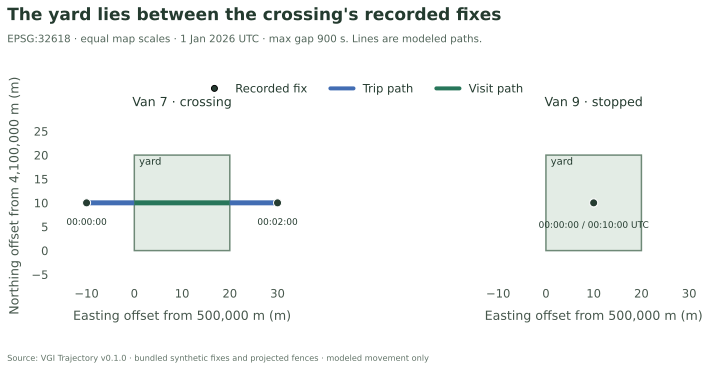

In [16]:
example.track_map(coverage, fence_shapes, spatial_paths, observations, MAX_GAP_S)


### Compare dwell, travel and uncertainty on one clock

Use a common time axis to avoid making the short crossing look as long as the stationary
track. Solid bars represent the model's visits and trips. Hatched bars are gaps, with no
reconstructed path or distance. Black marks identify actual observation times.

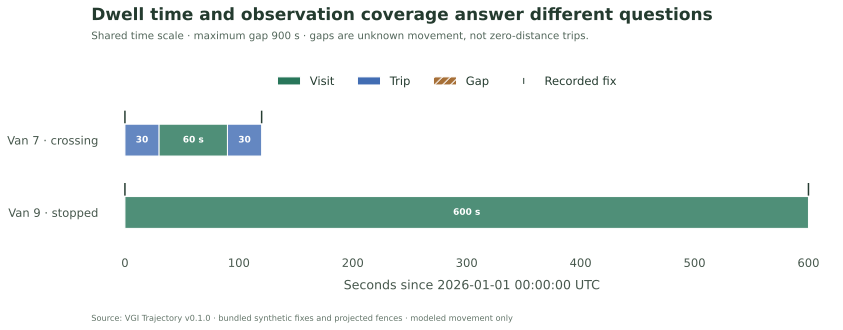

In [17]:
example.episode_timeline(coverage, episode_rows, observations, MAX_GAP_S)


In [18]:
%%sql totals <<
SELECT entity_id,
       sum(duration_s) FILTER (WHERE episode_type = 'visit') AS inferred_visit_s,
       sum(duration_s) FILTER (WHERE episode_type = 'trip') AS inferred_trip_s,
       sum(duration_s) FILTER (WHERE episode_type = 'gap') AS unknown_s,
       sum(distance_m) AS modeled_distance_m,
       count(*) FILTER (WHERE episode_type = 'gap') AS gap_episodes
FROM episodes GROUP BY entity_id ORDER BY entity_id;

In [19]:
display(totals)
prose(
    "**NULL means no episode of that type contributed to the sum.** "
    "A gap's distance is unavailable, whereas an accepted stationary visit has a measured model distance of zero. "
    "A sum of available distances covers only accepted intervals. "
    "Neither a missing visit nor a gap proves zero real dwell. "
    "For these single-fence, unfiltered inputs, visit + trip + gap durations partition each entity's observation span."
)

,entity_id,inferred_visit_s,inferred_trip_s,unknown_s,modeled_distance_m,gap_episodes
0,crossing,60.0,60.0,NaN,40.0,0
1,stopped,600.0,NaN,NaN,0.0,0


**NULL means no episode of that type contributed to the sum.** A gap's distance is unavailable, whereas an accepted stationary visit has a measured model distance of zero. A sum of available distances covers only accepted intervals. Neither a missing visit nor a gap proves zero real dwell. For these single-fence, unfiltered inputs, visit + trip + gap durations partition each entity's observation span.

### Check the model's internal accounting

A synthetic example should make its invariants visible. The following SQL compares
reported duration to timestamps, WKB path length to reported metres, and total episode
time to the source span. It also checks that gaps retain NULL geometry and distance.
These are consistency checks, not validation against an observed route.

The partition check is specific to **one fence and no minimum-dwell filter**. Overlapping
fences can double-count visit time; filtering short visits removes their time without
reassigning it to trips. Do not apply that invariant blindly to other inputs.

In [20]:
%%sql checks <<
WITH spans AS (
    SELECT entity_id, epoch(max(observed_at) - min(observed_at)) AS span_s
    FROM fixes GROUP BY entity_id
), accounting AS (
    SELECT e.entity_id, sum(duration_s) AS accounted_s,
           max(abs(duration_s - epoch(ended_at - started_at))) AS timestamp_error_s,
           max(abs(distance_m - ST_Length(ST_GeomFromWKB(geometry_wkb)))) AS path_error_m,
           count(*) FILTER (WHERE episode_type = 'gap' AND
               (distance_m IS NOT NULL OR geometry_wkb IS NOT NULL)) AS invalid_gaps,
           count(*) FILTER (WHERE episode_type != 'gap' AND
               (distance_m IS NULL OR geometry_wkb IS NULL)) AS invalid_paths
    FROM episodes e GROUP BY e.entity_id
)
SELECT a.*, s.span_s, abs(accounted_s - span_s) AS partition_error_s
FROM accounting a JOIN spans s USING (entity_id) ORDER BY entity_id;

In [21]:
display(checks)
assert not checks.empty
assert checks.timestamp_error_s.le(1e-6).all()
assert checks.partition_error_s.le(1e-6).all()
assert checks.path_error_m.dropna().le(1e-6).all()
assert checks.invalid_gaps.eq(0).all() and checks.invalid_paths.eq(0).all()
prose(
    f"**Consistency checks passed for {len(checks)} entities.** "
    "Reported times and available path lengths agree with the SQL recomputation. "
    "A NULL path-error value means there was no reconstructed path to compare, not a successful distance measurement."
)

,entity_id,accounted_s,timestamp_error_s,path_error_m,invalid_gaps,invalid_paths,span_s,partition_error_s
0,crossing,120.0,0.0,0.0,0,0,120.0,0.0
1,stopped,600.0,0.0,0.0,0,0,600.0,0.0


**Consistency checks passed for 2 entities.** Reported times and available path lengths agree with the SQL recomputation. A NULL path-error value means there was no reconstructed path to compare, not a successful distance measurement.

### Experiment · when should the model refuse to connect the dots?

**Change only `MAX_GAP_S` from 900 to 60**, then restart and run all. Predict what happens
to the crossing's inferred visit and to the stopped track before inspecting the result.
Compare the episode table and shared-clock chart, especially `status`, `distance_m` and
`unknown_s`. Restore **900.0** to reset the example.

The SQL below executes both controls on the same materialized fixes for a direct reference.
All other worker arguments retain exactly the settings used above. A shorter limit expresses
less willingness to infer between samples; it does not reveal the true route or prove the
longer-gap reconstruction wrong. Supplying more observations would be new evidence.

In [22]:
%%sql
CREATE OR REPLACE TABLE gap_experiment AS
SELECT 900.0 AS gap_limit_s, *
FROM trajectory.main.episodes((SELECT * FROM fixes),
    fences := 'demo://fences.json',
    input_crs := 'EPSG:32618', fence_crs := 'EPSG:32618', analysis_crs := 'EPSG:32618',
    max_gap_s := 900.0, max_speed_m_s := 80.0, max_accuracy_m := 100.0,
    min_dwell_s := 0.0, fence_buffer_m := 0.0)
UNION ALL
SELECT 60.0 AS gap_limit_s, *
FROM trajectory.main.episodes((SELECT * FROM fixes),
    fences := 'demo://fences.json',
    input_crs := 'EPSG:32618', fence_crs := 'EPSG:32618', analysis_crs := 'EPSG:32618',
    max_gap_s := 60.0, max_speed_m_s := 80.0, max_accuracy_m := 100.0,
    min_dwell_s := 0.0, fence_buffer_m := 0.0);

,Count


In [23]:
%%sql experiment <<
SELECT gap_limit_s, entity_id,
       sum(CASE WHEN episode_type = 'visit' THEN duration_s ELSE 0 END) AS inferred_visit_s,
       sum(CASE WHEN episode_type = 'trip' THEN duration_s ELSE 0 END) AS inferred_trip_s,
       sum(CASE WHEN episode_type = 'gap' THEN duration_s ELSE 0 END) AS unknown_s,
       sum(distance_m) AS modeled_distance_m,
       string_agg(DISTINCT status, ', ' ORDER BY status) AS status
FROM gap_experiment GROUP BY gap_limit_s, entity_id
ORDER BY entity_id, gap_limit_s DESC;

In [24]:
display(experiment)
loose = experiment.query("gap_limit_s == 900").set_index("entity_id")
strict = experiment.query("gap_limit_s == 60").set_index("entity_id")
prose(
    f"At **900 s**, the worker assigns {loose.inferred_visit_s.sum():.0f} s of visit time across the two tracks. "
    f"At **60 s**, it assigns {strict.inferred_visit_s.sum():.0f} s of visit time and "
    f"**{strict.unknown_s.sum():.0f} s of unknown movement**. Both records report `long_gap`; "
    "their distances are NULL. The sum across tracks is entity-time, not one vehicle's elapsed journey. "
    "The stopped track's identical endpoints do not make its unobserved interval safe to fill."
)
assert strict.inferred_visit_s.le(loose.inferred_visit_s).all()
assert strict.unknown_s.ge(loose.unknown_s).all()
assert np.allclose(
    experiment[["inferred_visit_s", "inferred_trip_s", "unknown_s"]].sum(axis=1),
    experiment.entity_id.map(coverage.set_index("entity_id").observed_span_s),
)

,gap_limit_s,entity_id,inferred_visit_s,inferred_trip_s,unknown_s,modeled_distance_m,status
0,900.0,crossing,60.0,60.0,0.0,40.0,linear_interpolation
1,60.0,crossing,0.0,0.0,120.0,NaN,long_gap
2,900.0,stopped,600.0,0.0,0.0,0.0,linear_interpolation
3,60.0,stopped,0.0,0.0,600.0,NaN,long_gap


At **900 s**, the worker assigns 660 s of visit time across the two tracks. At **60 s**, it assigns 0 s of visit time and **720 s of unknown movement**. Both records report `long_gap`; their distances are NULL. The sum across tracks is entity-time, not one vehicle's elapsed journey. The stopped track's identical endpoints do not make its unobserved interval safe to fill.

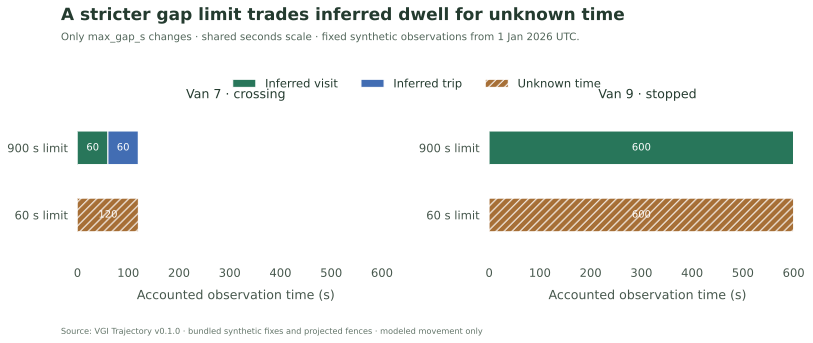

In [25]:
example.gap_comparison(coverage, experiment)


In [26]:
prose(
    f"**Your selected run uses {MAX_GAP_S:g} s.** "
    "Use the episode flags and coverage together: sampled membership, modeled dwell, and unknown time "
    "are three different claims. The crossing shows why a zero point count can miss a modeled visit; "
    "the experiment shows why interpolating every gap would overstate what the observations support."
)

**Your selected run uses 900 s.** Use the episode flags and coverage together: sampled membership, modeled dwell, and unknown time are three different claims. The crossing shows why a zero point count can miss a modeled visit; the experiment shows why interpolating every gap would overstate what the observations support.

In [27]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()


<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-trajectory](https://github.com/Query-farm/vgi-trajectory)
